# Predicting mobile video QoE (MOS) on the PoQeMoN dataset

**Objective.** Compare supervised models that predict the Mean Opinion Score (MOS, 1–5) of a mobile YouTube
session from the QoE influence factors in the PoQeMoN dataset, tune their hyperparameters with a systematic grid
search, and evaluate the selected model on a held-out test set.

**Structure** (mirrors the report):

1. Setup and configuration — seeds, paths, protocol constants
2. Data — source, feature groups, sanity checks
3. Exploratory analysis — target, distributions, relationships, user structure
4. Experimental protocol — feature sets, split, cross-validation, metrics, preprocessing
5. Models and hyperparameter grids
6. Results — model comparison, hyperparameter sensitivity, final test evaluation, feature importance
7. Limitations and next steps
8. Reproducibility

**How to run.** From the repository root: `jupyter nbconvert --to notebook --execute --inplace notebooks/poqemon-qoe-project.ipynb`
(or *Restart & Run All*). The notebook runs top to bottom with no manual changes. Figures are written to
`figures/` and result tables to `results/` for use in the report.

## 1. Setup and configuration

In [1]:
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, mean_absolute_error)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# ---- Protocol constants (everything that affects results is set here) ----
SEED = 42
DATA_URL = "https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv"
N_OUTER_SPLITS = 5      # one of 5 folds is held out as test set -> 80% train / 20% test
CV_FOLDS = 5            # inner cross-validation folds used by GridSearchCV
GROUP_BY_USER = True    # keep all sessions of a user in the same fold (see Section 4)
SELECTION_METRIC = "f1_macro"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "pokemon.csv"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 100, "savefig.dpi": 200,
                     "savefig.bbox": "tight"})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgb.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.14.4 | numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | xgboost 3.4.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Data

`pokemon.csv` from the [PoQeMoN QoE dataset](https://github.com/Lamyne/Poqemon-QoE-Dataset) (Amour et al.) was
collected in a crowdsourcing campaign: 181 testers watched YouTube videos on 9 Android devices over 4 French
operators and rated each session. According to the repository documentation, the columns are grouped into QoE
influence factors:

| Group | Columns | Meaning |
|---|---|---|
| — | `id`, `user_id` | Session and tester identifiers |
| QoA | `QoA_VLC*`, `QoA_BUFFERING*` | Application-level measurements from the VLC player (resolution, bitrate, frame rate, dropped frames, audio, stalls) |
| QoS | `QoS_type`, `QoS_operator` | Network technology (1 EDGE … 5 LTE) and operator (nominal code) |
| QoD | `QoD_model`, `QoD_os-version`, `QoD_api-level` | Device characteristics |
| QoU | `QoU_sex`, `QoU_age`, `QoU_Ustedy` | User profile |
| QoF | `QoF_begin`, `QoF_shift`, `QoF_audio`, `QoF_video` | **User feedback**: the tester's own 1–5 ratings of start-up, shifting, audio and video |
| Target | `MOS` | Overall opinion score, 1 (Bad) – 5 (Excellent) |

The file is downloaded once and cached in `data/`.

In [2]:
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]} sessions, {df.shape[1]} columns")
df.head()

1543 sessions, 23 columns


,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
0,590,71,360,528.39294,24.950000,0,43.800000,0,2,683,...,4.1.1(122573.16),16,1,20,5,3,5,3,4,3
1,428,46,360,402.64664,30.066667,0,44.200000,0,2,690,...,4.4.2(I9195XXUCNK1),19,1,25,5,4,5,5,5,5
2,406,44,360,735.84070,24.200000,0,44.183333,0,2,840,...,4.1.2(I9300XXELL4),16,1,22,5,3,5,4,4,4
3,1256,133,240,529.48830,24.116667,9,43.850000,0,2,868,...,4.4.4(suv3Rw),19,1,31,5,4,5,5,5,5
4,244,22,360,736.00085,24.066667,0,43.850000,0,2,869,...,4.1.2(I9300XXELL4),16,0,26,5,5,5,4,5,5


In [3]:
checks = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
})
print(f"Missing values: {df.isna().sum().sum()} | "
      f"duplicate sessions (ignoring id): {df.drop(columns='id').duplicated().sum()}")
checks

Missing values: 0 | duplicate sessions (ignoring id): 1


,dtype,n_unique,n_missing
id,int64,1543,0
user_id,int64,181,0
QoA_VLCresolution,int64,3,0
QoA_VLCbitrate,float64,1535,0
QoA_VLCframerate,float64,309,0
QoA_VLCdropped,int64,35,0
QoA_VLCaudiorate,float64,193,0
QoA_VLCaudioloss,int64,13,0
QoA_BUFFERINGcount,int64,9,0
QoA_BUFFERINGtime,int64,1327,0


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,1543.0,924.26,525.49,52.0,472.50,897.00,1298.50,2077.00
user_id,1543.0,98.13,50.67,1.0,53.00,117.00,135.00,181.00
QoA_VLCresolution,1543.0,354.57,25.94,16.0,360.00,360.00,360.00,360.00
QoA_VLCbitrate,1543.0,520.52,350.96,0.0,307.67,474.00,661.49,3918.29
QoA_VLCframerate,1543.0,25.00,6.69,0.0,24.73,25.32,29.80,31.32
QoA_VLCdropped,1543.0,1.22,5.62,0.0,0.00,0.00,1.00,107.00
QoA_VLCaudiorate,1543.0,40.38,9.12,0.0,43.78,44.15,44.47,46.00
QoA_VLCaudioloss,1543.0,0.24,1.13,0.0,0.00,0.00,0.00,14.00
QoA_BUFFERINGcount,1543.0,1.39,0.90,1.0,1.00,1.00,2.00,10.00
QoA_BUFFERINGtime,1543.0,6164.18,15032.23,683.0,2010.50,2719.00,4067.00,329271.00


## 3. Exploratory analysis

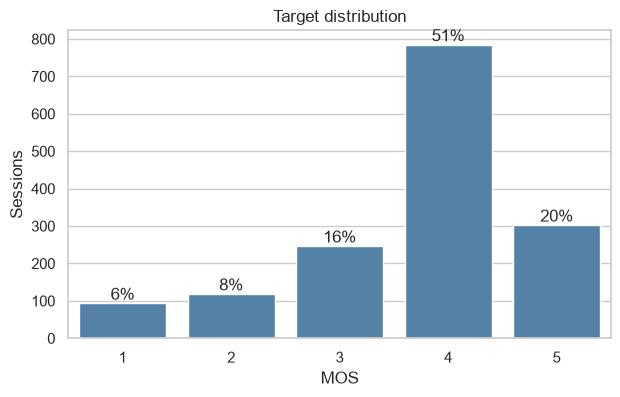

Majority class (MOS=4) share: 50.8%


In [5]:
mos_counts = df["MOS"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=mos_counts.index, y=mos_counts.values, color="steelblue", ax=ax)
for i, v in enumerate(mos_counts.values):
    ax.text(i, v + 10, f"{v / len(df):.0%}", ha="center")
ax.set(xlabel="MOS", ylabel="Sessions", title="Target distribution")
save_fig(fig, "mos_distribution")
plt.show()
print(f"Majority class (MOS={mos_counts.idxmax()}) share: {mos_counts.max() / len(df):.1%}")

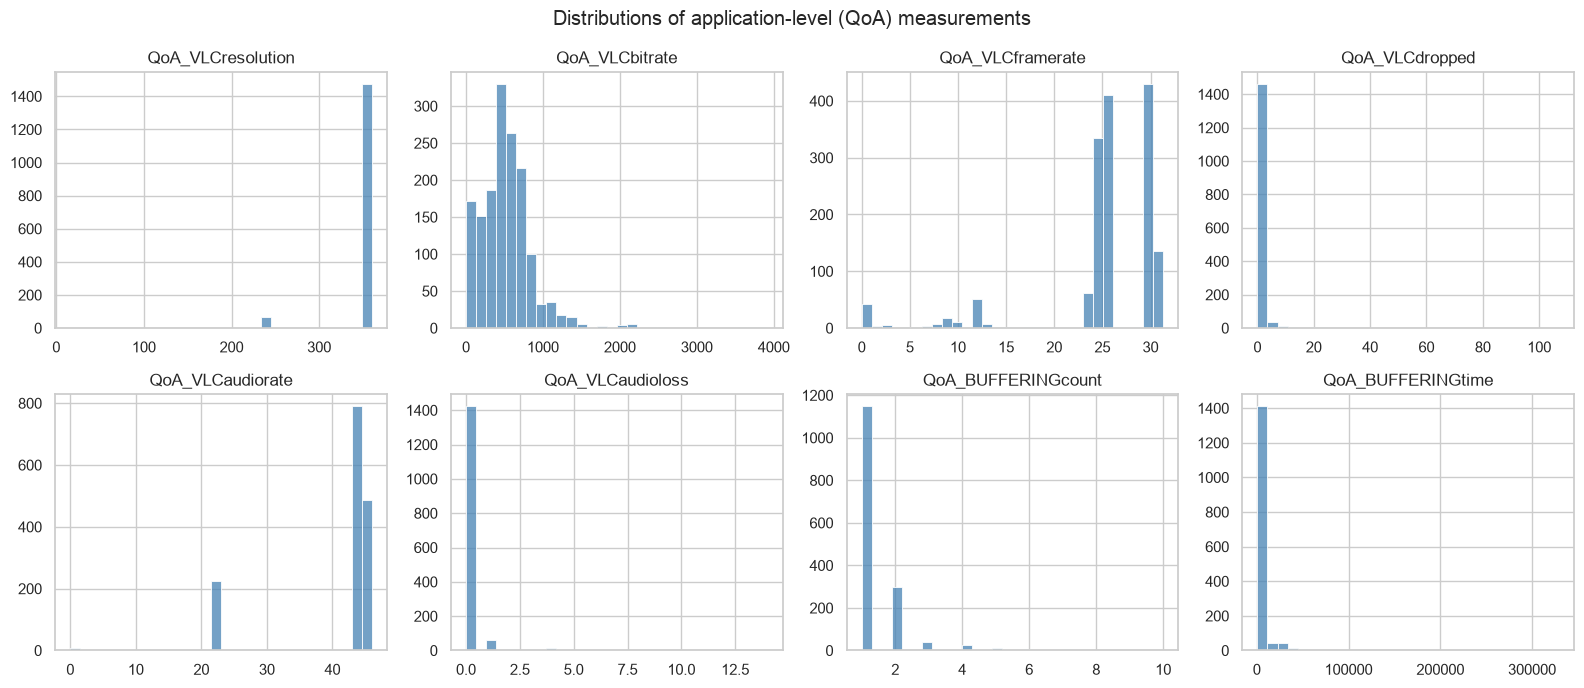

,skewness
QoA_VLCdropped,11.03
QoA_BUFFERINGtime,9.88
QoA_VLCaudioloss,6.67
QoA_BUFFERINGcount,3.82
QoA_VLCbitrate,2.70
QoA_VLCaudiorate,-2.02
QoA_VLCframerate,-2.24
QoA_VLCresolution,-5.18


In [6]:
measure_cols = [c for c in df.columns if c.startswith("QoA_")]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, measure_cols):
    sns.histplot(df[col], ax=ax, color="steelblue", bins=30)
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Distributions of application-level (QoA) measurements")
fig.tight_layout()
save_fig(fig, "qoa_distributions")
plt.show()

df[measure_cols].skew().sort_values(ascending=False).round(2).to_frame("skewness")

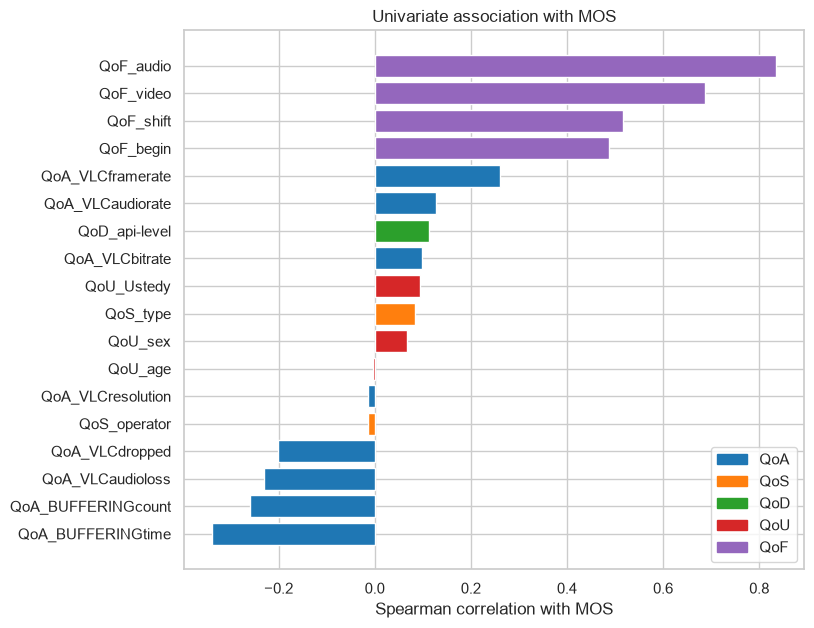

In [7]:
# Spearman correlation: MOS is ordinal and several features are heavy-tailed
group_of = lambda c: c.split("_")[0]
num_features = df.drop(columns=["id", "user_id", "MOS"]).select_dtypes("number").columns
corr = df[num_features].corrwith(df["MOS"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
palette = dict(zip(["QoA", "QoS", "QoD", "QoU", "QoF"], sns.color_palette("tab10", 5)))
ax.barh(corr.index, corr.values, color=[palette[group_of(c)] for c in corr.index])
ax.set(xlabel="Spearman correlation with MOS", title="Univariate association with MOS")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()],
          labels=palette.keys(), loc="lower right")
save_fig(fig, "spearman_with_mos")
plt.show()

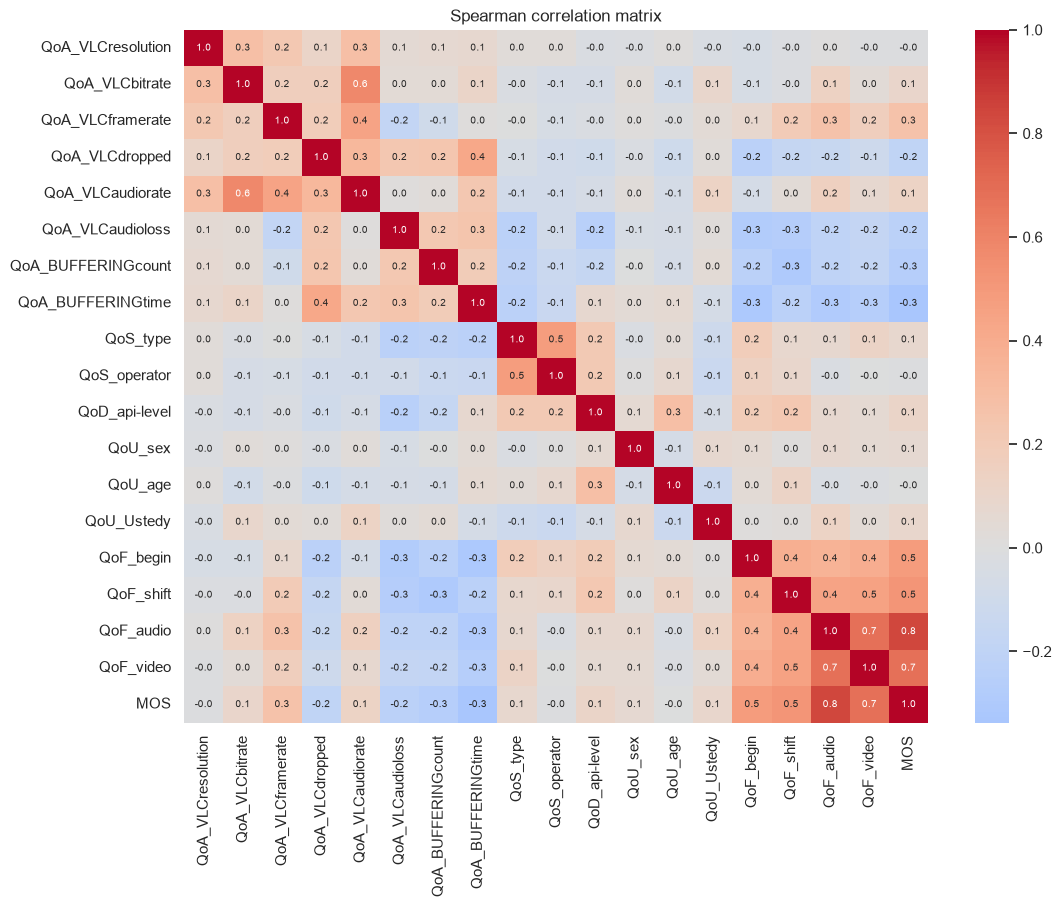

In [8]:
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(df[num_features.tolist() + ["MOS"]].corr(method="spearman"), cmap="coolwarm",
            center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation matrix")
save_fig(fig, "spearman_matrix")
plt.show()

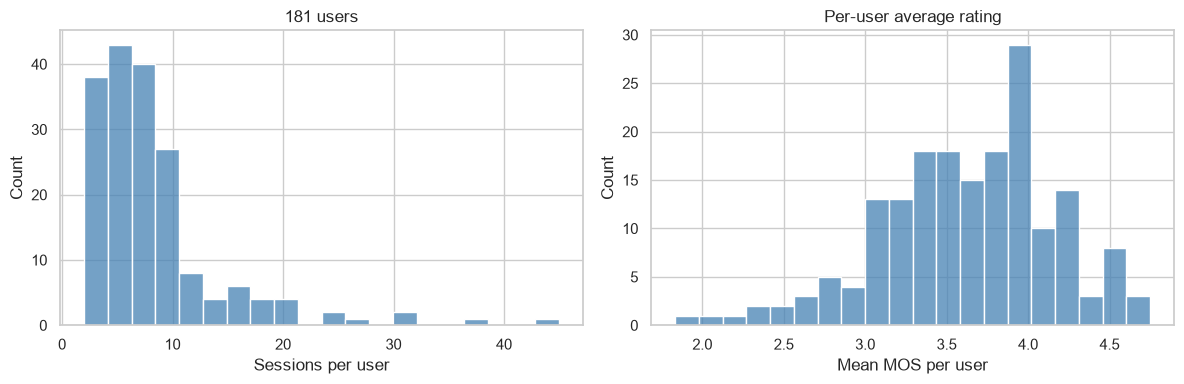

Share of MOS variance explained by user means: 24.5%


In [9]:
# Repeated measures: how many sessions per tester, and how much of MOS is explained by the tester?
per_user = df.groupby("user_id")["MOS"].agg(["size", "mean", "std"])
between_user_share = df.groupby("user_id")["MOS"].transform("mean").var() / df["MOS"].var()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(per_user["size"], bins=20, ax=axes[0], color="steelblue")
axes[0].set(xlabel="Sessions per user", title=f"{len(per_user)} users")
sns.histplot(per_user["mean"], bins=20, ax=axes[1], color="steelblue")
axes[1].set(xlabel="Mean MOS per user", title="Per-user average rating")
fig.tight_layout()
save_fig(fig, "user_structure")
plt.show()
print(f"Share of MOS variance explained by user means: {between_user_share:.1%}")

In [10]:
cat_summary = df.groupby("QoD_model")["MOS"].agg(["size", "mean"]).sort_values("size", ascending=False)
cat_summary.round(2)

,size,mean
QoD_model,,
D5803,576,3.85
GT-I9195,338,3.74
GT-I9300,181,3.66
HTC One X+,159,3.33
SM-G900F,112,3.72
ARCHOS 101G9,55,2.96
Nexus 4,55,3.64
SM-N9005,37,3.97
HTC One_M8,24,3.79


### EDA findings and how they guide the modelling

<!-- Numbers below come from the executed outputs above; re-check them if the data or seed changes. -->

1. **Clean data, imbalanced ordinal target.** No missing values and one duplicated session. MOS = 4 covers
   about half the sessions and MOS 1–2 together about 14%. A majority-class predictor already reaches ~51%
   accuracy, so we (a) report a dummy baseline, (b) select models on **macro-F1**, which weights rare classes
   equally, (c) stratify every split on MOS, and (d) report the **MAE** in MOS points because, for an
   ordinal target, predicting 4 instead of 5 is less wrong than predicting 1.
2. **QoF columns dominate.** The four user-feedback ratings have by far the strongest association with
   MOS (Spearman ≈ 0.5–0.85). They are subjective answers given by the same tester in the same questionnaire
   as MOS, so they are not available when predicting QoE for a new session, and they leak much of the target.
   We therefore compare two feature sets (Section 4).
3. **Among measurable factors, stalls and frame rate matter most.** Buffering time and count, audio loss and
   dropped frames are negatively associated with MOS; frame rate and audio rate positively. Network and
   device factors have weak univariate association.
4. **Heavy-tailed measurements.** Buffering time, dropped frames and audio loss are strongly right-skewed. We
   apply `log1p` to them before standardisation so that distance-based models (kNN, SVC) are not dominated
   by a few extreme sessions.
5. **Nominal categorical variables.** `QoD_model`, `QoD_os-version` and `QoS_operator` are labels without
   order, so they are **one-hot encoded** instead of being label-encoded (which would impose a false order on
   kNN/SVC distances).
6. **Repeated measures per user.** 181 testers contribute 2–45 sessions each, and testers differ in their
   average rating. If sessions of the same user appear in both training and test data, the model can partly
   memorise user habits (via age/sex/device) and the score overestimates performance on new users. All splits
   are therefore **grouped by `user_id`**.

## 4. Experimental protocol

| Element | Choice | Justification |
|---|---|---|
| Task | 5-class classification of MOS | MOS is a discrete 1–5 rating; MAE is reported to account for ordinality |
| Excluded columns | `id`, `user_id` (used only for grouping) | Identifiers, no causal information |
| Feature sets | **`objective`**: QoA + QoS + QoD + QoU (16 columns)  ·  **`with_feedback`**: objective + QoF (20 columns) | `objective` is the realistic setting (predict QoE without asking the user); `with_feedback` quantifies how much the subjective ratings add |
| Test split | 20% of users held out with `StratifiedGroupKFold` (one of 5 folds), fixed seed | Test users are never seen during training or tuning; touched **once**, at the end |
| Model selection | `GridSearchCV`, 5-fold `StratifiedGroupKFold` on the training users | Uses all training data for tuning; grouped folds give honest estimates of generalisation to new users |
| Selection metric | Macro-F1 (accuracy and MAE also reported) | Class imbalance (see EDA) |
| Preprocessing | `log1p` on skewed counts → `StandardScaler` on numeric; `OneHotEncoder` on nominal columns | Fitted **inside** the pipeline so each CV fold is preprocessed with its own training statistics (no leakage) |
| Seeds | `SEED = 42` for splits and all stochastic models | Reproducibility |

Compared with the earlier draft (single random 60/20/20 split, scaler fitted outside CV, label encoding of
device names), this protocol removes preprocessing leakage, uses the 20% formerly reserved for validation as
training data, and avoids user overlap between training and test data.

In [11]:
ID_COLS = ["id", "user_id"]
TARGET = "MOS"
QOF_COLS = [c for c in df.columns if c.startswith("QoF_")]
OBJECTIVE_COLS = [c for c in df.columns if c not in ID_COLS + QOF_COLS + [TARGET]]
FEATURE_SETS = {"objective": OBJECTIVE_COLS, "with_feedback": OBJECTIVE_COLS + QOF_COLS}

NOMINAL_COLS = ["QoD_model", "QoD_os-version", "QoS_operator"]
SKEWED_COLS = ["QoA_VLCdropped", "QoA_VLCaudioloss", "QoA_BUFFERINGcount", "QoA_BUFFERINGtime"]

X_all = df.drop(columns=ID_COLS + [TARGET])
y_all = df[TARGET] - 1          # classes 0..4 (required by XGBoost); add 1 back when reporting MOS
groups_all = df["user_id"]

if GROUP_BY_USER:
    outer = StratifiedGroupKFold(n_splits=N_OUTER_SPLITS, shuffle=True, random_state=SEED)
    train_idx, test_idx = next(outer.split(X_all, y_all, groups_all))
    cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
else:
    outer = StratifiedKFold(n_splits=N_OUTER_SPLITS, shuffle=True, random_state=SEED)
    train_idx, test_idx = next(outer.split(X_all, y_all))
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
groups_train = groups_all.iloc[train_idx]

assert not set(groups_train) & set(groups_all.iloc[test_idx]) or not GROUP_BY_USER
pd.DataFrame({
    "train": (y_train + 1).value_counts(normalize=True).sort_index(),
    "test": (y_test + 1).value_counts(normalize=True).sort_index(),
}).round(3).rename_axis("MOS").T.assign(
    sessions=[len(y_train), len(y_test)],
    users=[groups_train.nunique(), groups_all.iloc[test_idx].nunique()],
)

MOS,1,2,3,4,5,sessions,users
train,0.061,0.077,0.160,0.508,0.195,1239,148
test,0.059,0.076,0.158,0.510,0.197,304,33


In [12]:
def make_preprocessor(feature_cols):
    nominal = [c for c in NOMINAL_COLS if c in feature_cols]
    skewed = [c for c in SKEWED_COLS if c in feature_cols]
    numeric = [c for c in feature_cols if c not in nominal + skewed]
    return ColumnTransformer([
        ("skewed", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("scale", StandardScaler())]), skewed),
        ("numeric", StandardScaler(), numeric),
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal),
    ])

## 5. Models and hyperparameter grids

| Model | Why it is included | Grid |
|---|---|---|
| Dummy (most frequent) | Reference: any useful model must beat it | — |
| k-nearest neighbours | Non-parametric, local similarity between sessions | `n_neighbors` ∈ {3, 5, 7, 9, 11, 15, 21}, `weights` ∈ {uniform, distance} |
| SVC | Linear and non-linear (RBF) margins; robust in moderate dimension | `kernel` ∈ {linear, rbf}, `C` ∈ {0.1, 1, 10, 100}, `gamma` ∈ {scale, 0.01, 0.1} (RBF only) |
| Decision tree | Interpretable, captures thresholds such as "more than N stalls" | `max_depth` ∈ {3, 5, 7, 10, None}, `min_samples_leaf` ∈ {1, 5, 10, 20} |
| XGBoost | Gradient-boosted trees, usually strong on tabular data | `max_depth` ∈ {2, 3, 5}, `learning_rate` ∈ {0.05, 0.1, 0.2}, `n_estimators` ∈ {50, 100, 200}, `subsample` ∈ {0.8, 1.0} |

`class_weight="balanced"` is not used, so that the models are compared on equal footing (XGBoost has no
direct equivalent); see Limitations.

In [13]:
MODELS = {
    "Dummy": (DummyClassifier(strategy="most_frequent"), {}),
    "kNN": (KNeighborsClassifier(), {
        "clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
        "clf__weights": ["uniform", "distance"],
    }),
    "SVC": (SVC(random_state=SEED), [
        {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10, 100]},
        {"clf__kernel": ["rbf"], "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
    ]),
    "Decision tree": (DecisionTreeClassifier(random_state=SEED), {
        "clf__max_depth": [3, 5, 7, 10, None],
        "clf__min_samples_leaf": [1, 5, 10, 20],
    }),
    "XGBoost": (xgb.XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="mlogloss"), {
        "clf__max_depth": [2, 3, 5],
        "clf__learning_rate": [0.05, 0.1, 0.2],
        "clf__n_estimators": [50, 100, 200],
        "clf__subsample": [0.8, 1.0],
    }),
}

SCORING = {"f1_macro": "f1_macro", "accuracy": "accuracy", "mae": "neg_mean_absolute_error"}

In [14]:
searches = {}   # (feature_set, model) -> fitted GridSearchCV
for fs_name, cols in FEATURE_SETS.items():
    for model_name, (estimator, grid) in MODELS.items():
        pipe = Pipeline([("prep", make_preprocessor(cols)), ("clf", estimator)])
        search = GridSearchCV(pipe, grid, scoring=SCORING, refit=SELECTION_METRIC, cv=cv, n_jobs=-1)
        search.fit(X_train[cols], y_train, groups=groups_train)
        searches[fs_name, model_name] = search
        print(f"[{fs_name:13s}] {model_name:13s} CV macro-F1 = {search.best_score_:.3f}  "
              f"{ {k.removeprefix('clf__'): v for k, v in search.best_params_.items()} }")

[objective    ] Dummy         CV macro-F1 = 0.135  {}


[objective    ] kNN           CV macro-F1 = 0.450  {'n_neighbors': 5, 'weights': 'uniform'}


[objective    ] SVC           CV macro-F1 = 0.431  {'C': 100, 'gamma': 0.1, 'kernel': 'rbf'}


[objective    ] Decision tree CV macro-F1 = 0.466  {'max_depth': None, 'min_samples_leaf': 20}


[objective    ] XGBoost       CV macro-F1 = 0.490  {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
[with_feedback] Dummy         CV macro-F1 = 0.135  {}


[with_feedback] kNN           CV macro-F1 = 0.616  {'n_neighbors': 5, 'weights': 'uniform'}


[with_feedback] SVC           CV macro-F1 = 0.715  {'C': 0.1, 'kernel': 'linear'}


[with_feedback] Decision tree CV macro-F1 = 0.711  {'max_depth': 5, 'min_samples_leaf': 10}


[with_feedback] XGBoost       CV macro-F1 = 0.774  {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}


## 6. Results

### 6.1 Cross-validated comparison (training users only)

In [15]:
rows = []
for (fs_name, model_name), s in searches.items():
    i = s.best_index_
    r = s.cv_results_
    rows.append({
        "feature_set": fs_name, "model": model_name,
        "cv_f1_macro": r["mean_test_f1_macro"][i], "cv_f1_macro_std": r["std_test_f1_macro"][i],
        "cv_accuracy": r["mean_test_accuracy"][i], "cv_accuracy_std": r["std_test_accuracy"][i],
        "cv_mae": -r["mean_test_mae"][i], "cv_mae_std": r["std_test_mae"][i],
        "best_params": {k.removeprefix("clf__"): v for k, v in s.best_params_.items()},
    })
cv_summary = pd.DataFrame(rows)
cv_summary.to_csv(RESULTS_DIR / "cv_summary.csv", index=False)
cv_summary.round(3)

,feature_set,model,cv_f1_macro,cv_f1_macro_std,cv_accuracy,cv_accuracy_std,cv_mae,cv_mae_std,best_params
0,objective,Dummy,0.135,0.002,0.507,0.010,0.690,0.016,{}
1,objective,kNN,0.450,0.020,0.520,0.020,0.572,0.020,"{'n_neighbors': 5, 'weights': 'uniform'}"
2,objective,SVC,0.431,0.022,0.477,0.014,0.627,0.024,"{'C': 100, 'gamma': 0.1, 'kernel': 'rbf'}"
3,objective,Decision tree,0.466,0.033,0.531,0.038,0.539,0.041,"{'max_depth': None, 'min_samples_leaf': 20}"
4,objective,XGBoost,0.490,0.009,0.544,0.030,0.531,0.024,"{'learning_rate': 0.2, 'max_depth': 5, 'n_esti..."
5,with_feedback,Dummy,0.135,0.002,0.507,0.010,0.690,0.016,{}
6,with_feedback,kNN,0.616,0.041,0.695,0.016,0.328,0.016,"{'n_neighbors': 5, 'weights': 'uniform'}"
7,with_feedback,SVC,0.715,0.047,0.778,0.045,0.235,0.049,"{'C': 0.1, 'kernel': 'linear'}"
8,with_feedback,Decision tree,0.711,0.036,0.770,0.043,0.250,0.052,"{'max_depth': 5, 'min_samples_leaf': 10}"
9,with_feedback,XGBoost,0.774,0.036,0.806,0.041,0.212,0.055,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."


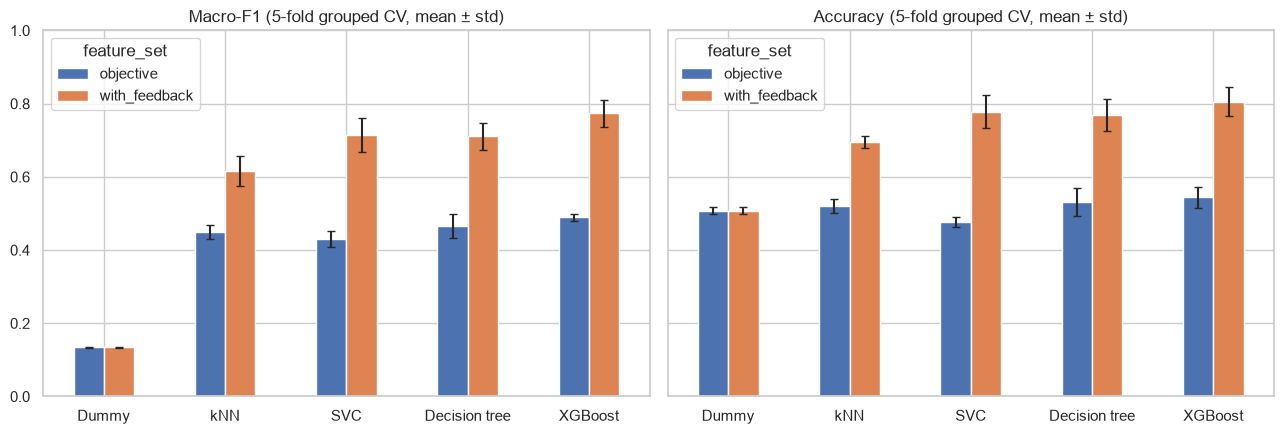

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (metric, label) in zip(axes, [("cv_f1_macro", "Macro-F1"), ("cv_accuracy", "Accuracy")]):
    pivot = cv_summary.pivot(index="model", columns="feature_set", values=metric).loc[list(MODELS)]
    err = cv_summary.pivot(index="model", columns="feature_set", values=f"{metric}_std").loc[list(MODELS)]
    pivot.plot.bar(yerr=err, ax=ax, capsize=3, rot=0)
    ax.set(title=f"{label} (5-fold grouped CV, mean ± std)", xlabel="", ylim=(0, 1))
fig.tight_layout()
save_fig(fig, "cv_comparison")
plt.show()

### 6.2 Hyperparameter sensitivity

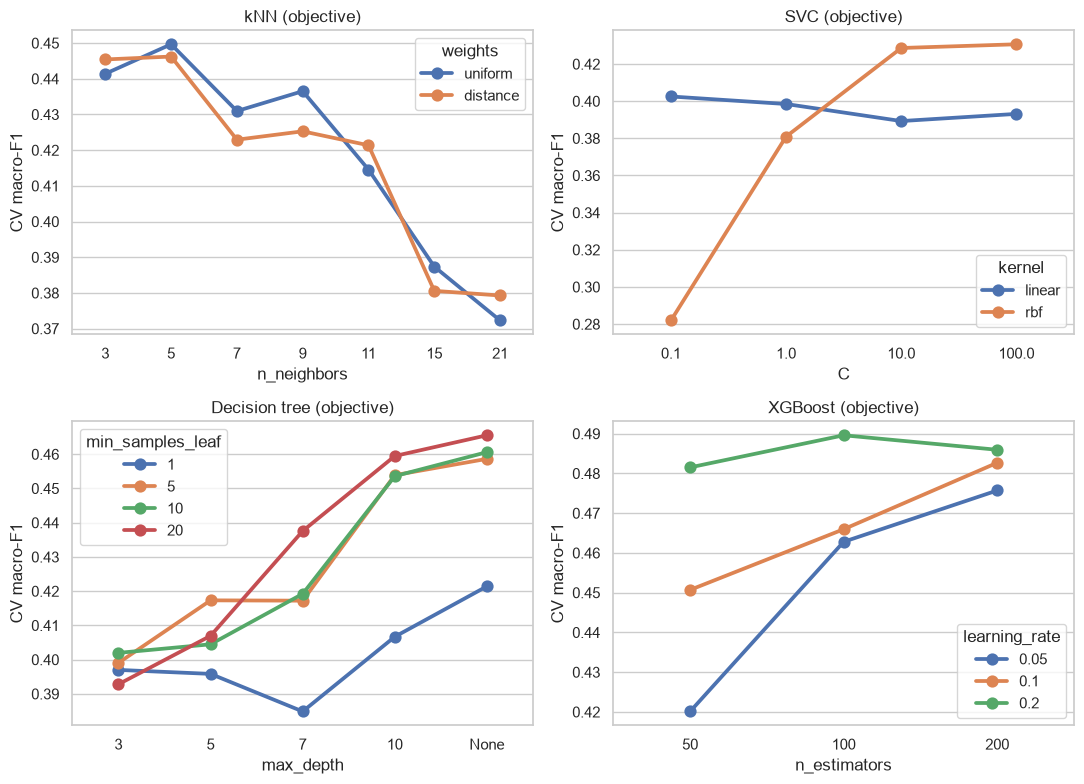

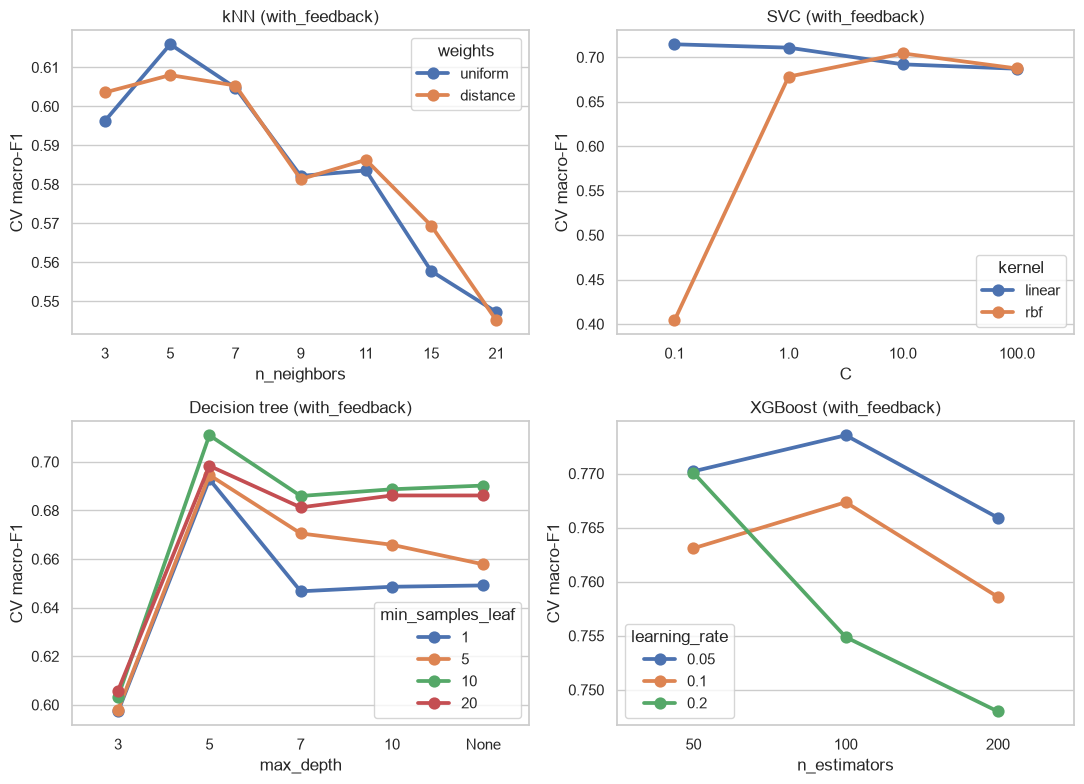

In [17]:
def plot_sensitivity(fs_name, model_name, x, hue, ax, fixed=None):
    res = pd.DataFrame(searches[fs_name, model_name].cv_results_)
    for k, v in (fixed or {}).items():
        res = res[res[f"param_clf__{k}"] == v]
    res = res.assign(**{c: res[f"param_clf__{c}"].astype(object).fillna("None").astype(str) for c in (x, hue)})
    best = res.groupby([x, hue], sort=False)["mean_test_f1_macro"].max().reset_index()
    sns.pointplot(best, x=x, y="mean_test_f1_macro", hue=hue, ax=ax)
    ax.set(title=f"{model_name} ({fs_name})", ylabel="CV macro-F1")

for fs_name in FEATURE_SETS:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    plot_sensitivity(fs_name, "kNN", "n_neighbors", "weights", axes[0, 0])
    plot_sensitivity(fs_name, "SVC", "C", "kernel", axes[0, 1])
    plot_sensitivity(fs_name, "Decision tree", "max_depth", "min_samples_leaf", axes[1, 0])
    plot_sensitivity(fs_name, "XGBoost", "n_estimators", "learning_rate", axes[1, 1])
    fig.tight_layout()
    save_fig(fig, f"sensitivity_{fs_name}")
    plt.show()

### 6.3 Final evaluation on held-out test users

For each feature set, the model with the best CV macro-F1 is refitted on all training users (done by
`GridSearchCV(refit=...)`) and evaluated **once** on the test users. All models are shown on the test set for
transparency, but the selection was made on CV only.

In [18]:
test_rows = []
for (fs_name, model_name), s in searches.items():
    pred = s.predict(X_test[FEATURE_SETS[fs_name]])
    test_rows.append({
        "feature_set": fs_name, "model": model_name,
        "test_f1_macro": f1_score(y_test, pred, average="macro"),
        "test_accuracy": accuracy_score(y_test, pred),
        "test_mae": mean_absolute_error(y_test, pred),
    })
test_summary = pd.DataFrame(test_rows)

champions = cv_summary.loc[cv_summary.groupby("feature_set")["cv_f1_macro"].idxmax(), ["feature_set", "model"]]
test_summary["selected_by_cv"] = test_summary.set_index(["feature_set", "model"]).index.isin(
    champions.set_index(["feature_set", "model"]).index)
test_summary.to_csv(RESULTS_DIR / "test_summary.csv", index=False)
test_summary.round(3)

,feature_set,model,test_f1_macro,test_accuracy,test_mae,selected_by_cv
0,objective,Dummy,0.135,0.510,0.684,False
1,objective,kNN,0.366,0.470,0.622,False
2,objective,SVC,0.358,0.434,0.704,False
3,objective,Decision tree,0.447,0.513,0.572,False
4,objective,XGBoost,0.411,0.539,0.533,True
5,with_feedback,Dummy,0.135,0.510,0.684,False
6,with_feedback,kNN,0.518,0.628,0.431,False
7,with_feedback,SVC,0.626,0.737,0.296,False
8,with_feedback,Decision tree,0.635,0.730,0.289,False
9,with_feedback,XGBoost,0.689,0.753,0.266,True


=== XGBoost on 'objective' features ===
              precision    recall  f1-score   support

           1      0.474     0.500     0.486        18
           2      0.353     0.261     0.300        23
           3      0.395     0.312     0.349        48
           4      0.629     0.800     0.705       155
           5      0.303     0.167     0.215        60

    accuracy                          0.539       304
   macro avg      0.431     0.408     0.411       304
weighted avg      0.498     0.539     0.508       304

=== XGBoost on 'with_feedback' features ===
              precision    recall  f1-score   support

           1      0.706     0.667     0.686        18
           2      0.538     0.609     0.571        23
           3      0.636     0.583     0.609        48
           4      0.824     0.845     0.834       155
           5      0.759     0.733     0.746        60

    accuracy                          0.753       304
   macro avg      0.693     0.687     0.689    

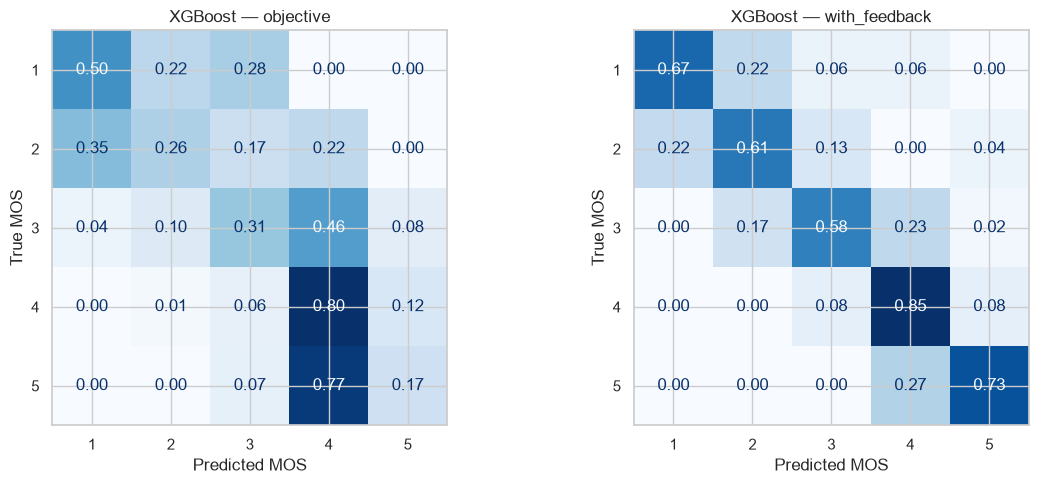

In [19]:
fig, axes = plt.subplots(1, len(champions), figsize=(12, 5))
for ax, (_, row) in zip(axes, champions.iterrows()):
    s = searches[row.feature_set, row.model]
    pred = s.predict(X_test[FEATURE_SETS[row.feature_set]])
    ConfusionMatrixDisplay.from_predictions(y_test + 1, pred + 1, normalize="true", values_format=".2f",
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=f"{row.model} — {row.feature_set}", xlabel="Predicted MOS", ylabel="True MOS")
    print(f"=== {row.model} on '{row.feature_set}' features ===")
    print(classification_report(y_test + 1, pred + 1, digits=3, zero_division=0))
fig.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

### 6.4 Which factors drive the predictions?

Permutation importance of the selected models on the test users (drop in macro-F1 when a column is shuffled,
10 repeats). It is computed on the raw input columns, so one-hot encoded variables are assessed as a whole.

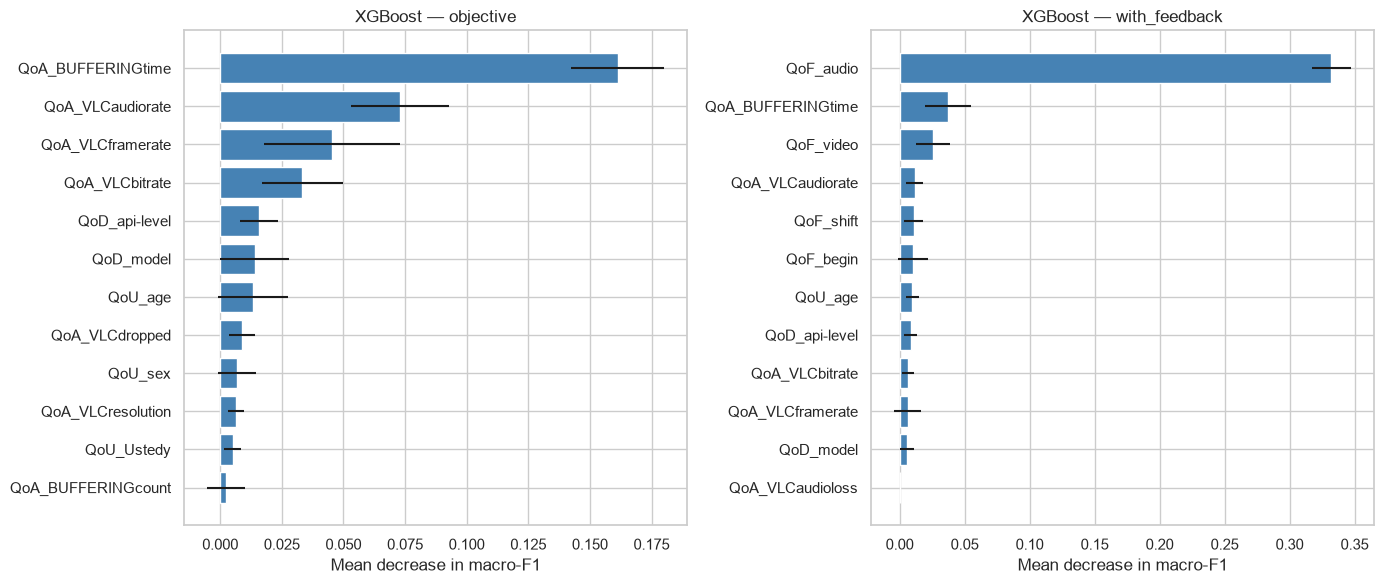

In [20]:
fig, axes = plt.subplots(1, len(champions), figsize=(14, 6))
for ax, (_, row) in zip(axes, champions.iterrows()):
    cols = FEATURE_SETS[row.feature_set]
    pi = permutation_importance(searches[row.feature_set, row.model].best_estimator_, X_test[cols], y_test,
                                scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=cols).sort_values().tail(12)
    ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=cols)[imp.index], color="steelblue")
    ax.set(title=f"{row.model} — {row.feature_set}", xlabel="Mean decrease in macro-F1")
fig.tight_layout()
save_fig(fig, "permutation_importance")
plt.show()

### 6.5 Does grouping by user matter?

The selected configurations are re-evaluated on the **training users only** (the test set stays untouched)
with repeated 5-fold CV (5 repetitions), once with folds stratified on MOS only (`random`) and once with folds
grouped by user (`grouped`).

In [21]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

rows = []
for _, row in champions.iterrows():
    cols = FEATURE_SETS[row.feature_set]
    est = clone(searches[row.feature_set, row.model].best_estimator_)
    for split, splitter in [("random", StratifiedKFold), ("grouped", StratifiedGroupKFold)]:
        for rep in range(5):
            cv_rep = splitter(n_splits=CV_FOLDS, shuffle=True, random_state=SEED + rep)
            r = cross_validate(est, X_train[cols], y_train, cv=cv_rep, n_jobs=-1,
                               groups=groups_train if split == "grouped" else None,
                               scoring=["f1_macro", "accuracy"])
            rows += [{"feature_set": row.feature_set, "split": split, "f1_macro": f, "accuracy": a}
                     for f, a in zip(r["test_f1_macro"], r["test_accuracy"])]
split_effect = (pd.DataFrame(rows).groupby(["feature_set", "split"])
                .agg(f1_macro=("f1_macro", "mean"), f1_macro_std=("f1_macro", "std"),
                     accuracy=("accuracy", "mean"), accuracy_std=("accuracy", "std")))
split_effect.to_csv(RESULTS_DIR / "split_effect.csv")
split_effect.round(3)

f1_macro  f1_macro_std  accuracy  accuracy_std
feature_set   split                                                  
objective     grouped     0.474         0.046     0.542         0.035
              random      0.487         0.034     0.564         0.022
with_feedback grouped     0.769         0.041     0.805         0.031
              random      0.763         0.036     0.803         0.025

### Interpretation

<!-- Written from the executed outputs; update if the protocol changes. -->

1. **Subjective feedback explains most of what the models can predict.** With the QoF ratings, XGBoost reaches a
   test macro-F1 of 0.69 (accuracy 0.75, MAE 0.27 MOS points). Without them the best result drops to
   macro-F1 ≈ 0.41–0.45 (accuracy 0.54, MAE 0.53). For comparison, the majority-class baseline gets
   accuracy 0.51 and MAE 0.68. Permutation importance shows that `QoF_audio` alone carries most of the
   `with_feedback` model, which is consistent with the EDA (Spearman 0.84 with MOS).
2. **From measurable factors, stalls dominate.** In the `objective` setting the most important input by far is
   buffering time, followed by audio rate, frame rate and bitrate. This agrees with the QoE literature, where
   rebuffering is the main impairment of video streaming. Network and device descriptors add little once the
   player-level measurements are known.
3. **Model ranking.** XGBoost has the best CV macro-F1 in both settings and the lowest MAE. Distance-based models
   (kNN, SVC) are clearly weaker without feedback. In the `objective` setting the decision tree scores higher
   than XGBoost on the test users (0.45 vs 0.41 macro-F1). With only 33 test users this difference is within the
   CV standard deviation, so the CV-based selection stands. It still shows how noisy a single test split is.
4. **Errors are mostly between neighbouring classes.** The confusion matrices show most errors one MOS point
   away. Without feedback, the model predicts MOS 4 too often (recall 0.80 for MOS 4, 0.17 for MOS 5): from
   network and player measurements alone, "good" and "excellent" sessions look alike.
5. **Effect of the grouped split** (Section 6.5). With the objective features, random CV scores slightly
   higher than user-grouped CV (about +0.01 macro-F1 and +0.02 accuracy). The direction is the expected one:
   user overlap inflates the scores. The size is within one standard deviation, though. With feedback
   features the two schemes agree. The earlier draft's 0.80 test accuracy (random split) against 0.75 here is
   therefore mostly variance from the single test split. The grouped split stays the protocol of choice
   because it matches the use case (new users).
6. **Hyperparameters.** Without feedback the models prefer high capacity: RBF-SVC with large `C`, deep trees
   (`max_depth=None` with `min_samples_leaf=20`), and XGBoost with `learning_rate=0.2`, `max_depth=5`. Several
   optima lie on the edge of the grid (`C=100`, `learning_rate=0.2`), so extending these grids is a sensible
   next experiment. With feedback, simple models suffice: linear SVC with `C=0.1`, depth-2 boosted trees.

## 7. Limitations and next steps

- **Small, imbalanced data.** 1,543 sessions from 181 users; only ~19 test sessions per class for MOS 1. Test
  scores have wide uncertainty (a single held-out split). Repeated grouped splits or nested CV would give
  confidence intervals.
- **Ordinal target treated as nominal.** Classifiers ignore that 4 is closer to 5 than to 1. Regression or
  ordinal models (e.g. predicting MOS as a continuous value and rounding) are a natural extension; we report MAE
  to partly account for it.
- **Feedback features.** The `with_feedback` results are an upper bound. They are not applicable when QoE has
  to be estimated without asking the user.
- **User effects.** Testers rate systematically higher or lower. Grouped splitting measures generalisation to
  new users, but the models cannot correct for a new user's personal bias.
- **Class imbalance.** No re-weighting or resampling was applied; class weights or ordinal-aware losses
  could improve recall on MOS 1–2.
- **Single dataset.** One campaign around Paris, 9 devices, users aged 19–38 who were researchers or
  students. Results may not transfer to other populations, networks or players.

## 8. Reproducibility

- Data: downloaded from `DATA_URL` (cell 1) into `data/pokemon.csv` on first run.
- Seeds: `SEED = 42` controls the train/test split, the CV folds, SVC, the decision tree, XGBoost and
  permutation importance.
- Split: 80/20 grouped and stratified (`StratifiedGroupKFold`, first of 5 folds). Tuning uses 5-fold grouped CV
  on the training part only.
- Hyperparameter grids: Section 5. Best parameters: `results/cv_summary.csv`; test scores:
  `results/test_summary.csv`; grouped vs random CV: `results/split_effect.csv`.
- Software versions: printed in cell 1; pinned in `requirements.txt`.